[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nlavadodatasci/atd-megaf-fiabilidade/blob/main/T5_sistemas_reparaveis/T5_sistemas_reparaveis.ipynb)

# T5 — Sistemas reparáveis, manutibilidade e disponibilidade

**ATD — MEGAF 2026/27 · Atividade de Fiabilidade · Tema T5**

Um ativo reparável falha, é reparado e volta ao serviço, várias vezes ao longo da vida. Este *notebook* mostra, com duas máquinas **inventadas**, como calcular MTBF, MTTR e disponibilidade a partir de um registo de falhas, e como verificar se as falhas se estão a tornar mais frequentes.

**Como usar:** execute as células por ordem (Shift+Enter). As primeiras secções estão resolvidas, com dados da aula ou com exemplos inventados, para mostrar o método. A última secção, **A sua vez**, lê os dados da instalação e deixa pistas: o trabalho do grupo começa aí. O capítulo deste tema no documento de apoio explica cada passo.

## 1. Dois registos de falhas inventados

In [1]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

REPO = "https://raw.githubusercontent.com/nlavadodatasci/atd-megaf-fiabilidade/main/dados/"

def obter(ficheiro):
    """Vai buscar o ficheiro ao repositório. Se falhar, abre uma janela
    para o escolher no seu computador."""
    if not os.path.exists(ficheiro):
        try:
            urllib.request.urlretrieve(REPO + ficheiro, ficheiro)
        except Exception:
            from google.colab import files
            print("Escolha no seu computador o ficheiro", ficheiro)
            carregados = files.upload()
            if ficheiro not in carregados:               # veio com outro nome: renomeia
                os.rename(list(carregados)[0], ficheiro)
    return ficheiro

T_OBS = 6000          # cada máquina foi observada durante 6000 horas de funcionamento

# horas de funcionamento acumuladas à data de cada falha, e duração de cada reparação
maq_X = pd.DataFrame({"horas_acum": [450, 1100, 1500, 2300, 2900, 3400, 4300, 4800, 5600],
                      "reparacao_h": [5, 8, 3, 12, 6, 4, 9, 7, 5]})
maq_Y = pd.DataFrame({"horas_acum": [1500, 2700, 3600, 4300, 4800, 5200, 5500, 5750, 5950],
                      "reparacao_h": [6, 4, 9, 5, 7, 10, 6, 8, 5]})
maq_X

,horas_acum,reparacao_h
0,450,5
1,1100,8
2,1500,3
3,2300,12
4,2900,6
5,3400,4
6,4300,9
7,4800,7
8,5600,5


## 2. MTBF, MTTR e disponibilidade

- **MTBF** = horas de funcionamento / número de falhas
- **MTTR** = média dos tempos de reparação
- **Disponibilidade** $A = \dfrac{\text{MTBF}}{\text{MTBF} + \text{MTTR}}$ (documento base)

In [2]:
def indicadores(registo, t_obs):
    n = len(registo)
    mtbf = t_obs / n
    mttr = registo["reparacao_h"].mean()
    return {"falhas": n, "MTBF": mtbf, "MTTR": mttr, "disponibilidade": mtbf / (mtbf + mttr)}

pd.DataFrame({"Máquina X": indicadores(maq_X, T_OBS), "Máquina Y": indicadores(maq_Y, T_OBS)}).round(4)

,Máquina X,Máquina Y
falhas,9.0000,9.0000
MTBF,666.6667,666.6667
MTTR,6.5556,6.6667
disponibilidade,0.9903,0.9901


As duas máquinas têm o mesmo número de falhas e, por isso, o mesmo MTBF. Pelos indicadores, parecem iguais. Não são.

## 3. O MTBF esconde a tendência: gráfico de falhas acumuladas

Desenhe o número de falhas acumuladas em função das horas de funcionamento. Se a taxa de falha for constante, os pontos seguem aproximadamente uma reta. Se a curva dobra para cima, as falhas estão a ficar mais frequentes (o ativo está a degradar-se); se dobra para baixo, estão a ficar mais raras.

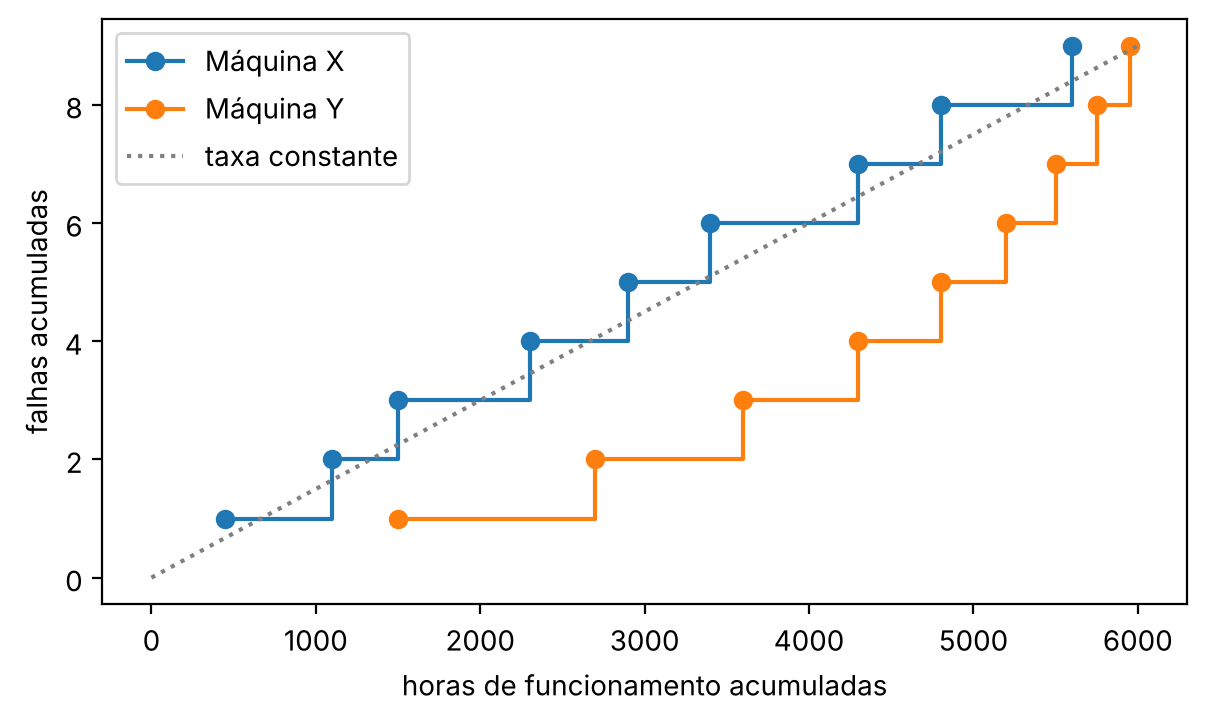

Tempos entre falhas, máquina X: [450 650 400 800 600 500 900 500 800]
Tempos entre falhas, máquina Y: [1500 1200  900  700  500  400  300  250  200]


In [3]:
plt.figure(figsize=(7, 3.8))
for nome, reg in [("Máquina X", maq_X), ("Máquina Y", maq_Y)]:
    plt.step(reg["horas_acum"], np.arange(1, len(reg) + 1), where="post", marker="o", label=nome)
plt.plot([0, T_OBS], [0, 9], color="gray", ls=":", label="taxa constante")
plt.xlabel("horas de funcionamento acumuladas"); plt.ylabel("falhas acumuladas"); plt.legend(); plt.show()

print("Tempos entre falhas, máquina X:", np.diff(maq_X["horas_acum"], prepend=0))
print("Tempos entre falhas, máquina Y:", np.diff(maq_Y["horas_acum"], prepend=0))

## 4. Teste de Laplace

O gráfico sugere; o teste de Laplace quantifica. Se não houver tendência, os instantes das falhas espalham-se uniformemente pelo período observado e a sua média fica perto de metade do período. A estatística é

$$U = \frac{\bar t - T/2}{T\sqrt{1/(12\,n)}}$$

em que $\bar t$ é a média dos instantes de falha, $T$ o período observado e $n$ o número de falhas. Sem tendência, $U$ segue aproximadamente uma normal padrão:

- $|U| < 1{,}96$: não há evidência de tendência (a 5 %);
- $U > 1{,}96$: as falhas concentram-se no fim, o ativo está a **degradar-se**;
- $U < -1{,}96$: as falhas concentram-se no início, o ativo está a **melhorar**.

In [4]:
def laplace(instantes, t_obs):
    instantes = np.asarray(instantes)
    n = len(instantes)
    U = (instantes.mean() - t_obs / 2) / (t_obs * np.sqrt(1 / (12 * n)))
    valor_p = 2 * stats.norm.sf(abs(U))
    return U, valor_p

for nome, reg in [("Máquina X", maq_X), ("Máquina Y", maq_Y)]:
    U, p = laplace(reg["horas_acum"], T_OBS)
    print(f"{nome}:  U = {U:5.2f}   valor-p = {p:.3f}")

Máquina X:  U = -0.13   valor-p = 0.900
Máquina Y:  U =  2.37   valor-p = 0.018


Na máquina X não há evidência de tendência: o MTBF resume bem o comportamento. Na máquina Y há degradação: o MTBF global é uma média de um passado bom e de um presente mau, e não serve para prever as próximas falhas.

## 5. A sua vez

Duas folhas de dados. Pistas para `reparacoes`:

1. Calcule o MTTR de cada tipo de componente e veja o histograma dos tempos de reparação. É simétrico?
2. Que distribuição descreve os tempos de reparação? (Use as funções do *notebook* `00_comum`.) O que significa, na prática, uma cauda longa à direita?
3. Para a disponibilidade de cada tipo de componente precisa também de um MTBF. De que folha o pode tirar?

Pistas para `historico_ativos` (dois compressores, observados durante 20 000 horas de funcionamento cada):

4. Calcule MTBF, MTTR e disponibilidade de cada compressor. São parecidos?
5. Faça o gráfico de falhas acumuladas e o teste de Laplace para cada um.
6. Para o compressor com tendência, compare o MTBF da primeira metade do período com o da segunda.
7. O que recomenda para cada compressor? Em qual deles o MTBF é um bom resumo?

In [5]:
rep = pd.read_excel(obter("dados_fiabilidade.xlsx"), sheet_name="reparacoes")
hist = pd.read_excel("dados_fiabilidade.xlsx", sheet_name="historico_ativos")
T_COMP = 20000                                 # horas de funcionamento observadas por compressor

print(rep.groupby("componente")["tempo_reparacao_h"].count())
print(hist.groupby("ativo")["n_falha"].count())

comp_A = hist[hist["ativo"] == "Compressor A"]
# laplace(comp_A["horas_funcionamento_acumuladas"], T_COMP)

componente
Controlador      40
Gerador          40
Interruptor      40
QGBT             40
Transformador    40
Name: tempo_reparacao_h, dtype: int64
ativo
Compressor A    23
Compressor B    26
Name: n_falha, dtype: int64
